# ToysAD-8K DS2 Confirmation Release

**Notebook file:** `08a-toysad8k-ds2-confirmation-release.ipynb`

This notebook prepares the untouched 300-scene development confirmation cohort. It keeps all 20 views, so the release contains 6,000 RGB images. It creates three physically separate resources: model-safe RGB, model-safe supplied geometry, and evaluator-only labels and attributes.

This stage does not run SAM, DINO, peer scoring, or model selection.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `08A DS2 confirmation release`  
Clean notebook SHA-256: `ab184d201a0a2d717af5e897004f2e7b21adaf463323f9bc769a777c5c3c952a`  
Downloaded saved-output SHA-256: `bb476e1ab5af5579d13f4a789cfa6298e332819fae5353ea65d6792c3d20da2f`


## Acceptance contract

- The cohort must match the frozen `confirm_300` membership hash.
- All 300 scenes and all 6,000 views must decode and pass checksums.
- RGB and supplied geometry must not contain anomaly labels, categories, raw source IDs, or experimental roles.
- Evaluator attributes must remain in a separate output resource.
- A second build must reuse the RGB files without changing the package identity.
- Only aggregate tables and charts may be sent to ClearML.

In [1]:
from __future__ import annotations

from hashlib import sha256
import json
import os
from pathlib import Path
import shutil
import subprocess
import sys

sys.dont_write_bytecode = True

from IPython.display import Image as NotebookImage, display

NOTEBOOK_NAME = "08a-toysad8k-ds2-confirmation-release.ipynb"
EXECUTION_ENVIRONMENT = "kaggle" if Path("/kaggle/input").is_dir() else "local"
OUTPUT_ROOT = Path(os.getenv(
    "VPI_OUTPUT_ROOT",
    "/kaggle/temp/toysad8k_ds2_confirmation_release" if EXECUTION_ENVIRONMENT == "kaggle" else ".local/runs/toysad8k-ds2-confirmation-release",
)).expanduser().resolve()

In [2]:
def kaggle_dataset_roots() -> list[Path]:
    input_root = Path("/kaggle/input")
    if not input_root.is_dir():
        return []
    candidates: list[Path] = []
    for pattern in (
        "*",
        "datasets/*/*",
        "datasets/*/*/versions/*",
        "notebooks/*/*",
        "notebooks/*/*/versions/*",
    ):
        candidates.extend(path for path in input_root.glob(pattern) if path.is_dir())
    return sorted(set(candidates), key=lambda path: path.as_posix())


def find_code_root() -> Path:
    configured = os.getenv("VPI_CODE_ROOT")
    candidates = [Path(configured).expanduser()] if configured else []
    candidates.extend((Path.cwd(), *Path.cwd().parents))
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for mounted in kaggle_dataset_roots():
            candidates.extend((mounted, mounted / "code"))
    for candidate in candidates:
        if (candidate / "src/visual_peer_inspector/data/cohort_contract.py").is_file():
            return candidate.resolve()
    mounted_names = sorted(path.name for path in input_root.iterdir()) if input_root.is_dir() else []
    raise FileNotFoundError(
        f"Could not locate the Visual Peer Inspector code snapshot. Mounted inputs: {mounted_names}"
    )


def find_package(package_kind: str, variable: str) -> Path:
    configured = os.getenv(variable)
    candidates = [Path(configured).expanduser()] if configured else []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for mounted in kaggle_dataset_roots():
            candidates.append(mounted)
            candidates.extend(
                child for child in sorted(mounted.iterdir()) if child.is_dir()
            )
    for candidate in candidates:
        record_path = candidate / "package_record.json"
        if not record_path.is_file():
            continue
        try:
            record = json.loads(record_path.read_text(encoding="utf-8"))
        except Exception:
            continue
        is_rgb_package = (
            package_kind == "toysad8k-model-input"
            and record.get("cohort_id") == "toysad8k-development-confirm-300-v1"
            and (candidate / "neutral_corpus_manifest.jsonl").is_file()
            and (candidate / "media").is_dir()
        )
        if record.get("package_kind") == package_kind or is_rgb_package:
            return candidate.resolve()
    raise FileNotFoundError(f"Could not locate package kind: {package_kind}")


def find_named_input_file(name: str, variable: str) -> Path:
    configured = os.getenv(variable)
    if configured:
        path = Path(configured).expanduser()
        if path.is_file():
            return path.resolve()
    patterns = (
        name,
        f"*/{name}",
        f"*/*/{name}",
        f"*/*/*/{name}",
        f"*/*/*/*/{name}",
    )
    matches = []
    for mounted in kaggle_dataset_roots():
        for pattern in patterns:
            matches.extend(path for path in mounted.glob(pattern) if path.is_file())
    unique = sorted(set(matches), key=lambda path: path.as_posix())
    if not unique:
        raise FileNotFoundError(f"Could not find mounted input file: {name}")
    digests = {sha256(path.read_bytes()).hexdigest() for path in unique}
    if len(digests) != 1:
        raise ValueError(f"Mounted copies of {name} do not match")
    preferred = sorted(
        unique,
        key=lambda path: ("downstream" not in path.parts, path.as_posix()),
    )
    return preferred[0].resolve()


def read_secret(name: str) -> str | None:
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return os.getenv(name)


def code_environment() -> dict[str, str]:
    environment = os.environ.copy()
    source_root = str(CODE_ROOT / "src")
    previous = environment.get("PYTHONPATH")
    environment["PYTHONPATH"] = source_root if not previous else source_root + os.pathsep + previous
    return environment


def run_clearml_finalizer(safe_root: Path, stage: str, task_name: str, tags: list[str], receipt: Path) -> dict:
    mode = "online" if EXECUTION_ENVIRONMENT == "kaggle" else "disabled"
    environment = code_environment()
    if mode == "online":
        access = read_secret("CLEARML_API_ACCESS_KEY")
        secret = read_secret("CLEARML_API_SECRET_KEY")
        if not access or not secret:
            mode = "disabled"
        else:
            environment.update({
                "CLEARML_API_ACCESS_KEY": access,
                "CLEARML_API_SECRET_KEY": secret,
                "CLEARML_API_HOST": "https://api.clear.ml",
                "CLEARML_WEB_HOST": "https://app.clear.ml",
                "CLEARML_FILES_HOST": "https://files.clear.ml",
            })
    command = [
        sys.executable,
        str(CODE_ROOT / "scripts/finalize_ds2_clearml.py"),
        "--safe-root", str(safe_root),
        "--receipt", str(receipt),
        "--stage", stage,
        "--task-name", task_name,
        "--mode", mode,
    ]
    for tag in tags:
        command.extend(("--tag", tag))
    try:
        subprocess.run(command, env=environment, check=True, timeout=240)
    except Exception as error:
        receipt.parent.mkdir(parents=True, exist_ok=True)
        receipt.write_text(json.dumps({
            "schema_version": 1,
            "status": "failed",
            "error_type": type(error).__name__,
            "task_id": None,
        }, indent=2) + "\\n", encoding="utf-8")
    return json.loads(receipt.read_text(encoding="utf-8"))

## Locate the trusted inputs

In [3]:
CODE_ROOT = find_code_root()
sys.path.insert(0, str(CODE_ROOT / "src"))


def find_directory(marker: str, variable: str) -> Path:
    # Resolve only roots carrying the exact trusted marker for this release stage.
    configured = os.getenv(variable)
    candidates = [Path(configured).expanduser()] if configured else []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for mounted in kaggle_dataset_roots():
            candidates.append(mounted)
            candidates.extend(
                child for child in sorted(mounted.iterdir()) if child.is_dir()
            )
    local_shared = CODE_ROOT.parent / "code" / ".local" / "toysad"
    candidates.extend((
        local_shared / "selection/toysad8k-train-2000-v2",
        local_shared / "selection/toysad8k-train-2000-v2-development",
        local_shared / "selection/toysad8k-train-2000-v2-administrative-vault",
        local_shared / "kaggle/toysad8k-full-private-v1",
    ))
    for candidate in candidates:
        if (candidate / marker).is_file():
            return candidate.resolve()
    raise FileNotFoundError(f"Could not locate {variable} containing {marker}")


SELECTION_ROOT = find_directory("neutral_corpus_manifest.jsonl", "VPI_SELECTION_ROOT")
DEVELOPMENT_ROOT = find_directory("development_source_map.jsonl", "VPI_DEVELOPMENT_ROOT")
ADMINISTRATIVE_ROOT = find_directory("required_source_members.jsonl", "VPI_ADMINISTRATIVE_ROOT")
SOURCE_ROOT = find_directory("archive_index.sqlite3", "VPI_SOURCE_ROOT")

from visual_peer_inspector.data.cohort_contract import DS2_CONFIRM_CONTRACT

display({
    "cohort": DS2_CONFIRM_CONTRACT.cohort_id,
    "scenes": DS2_CONFIRM_CONTRACT.scene_count,
    "views per scene": DS2_CONFIRM_CONTRACT.views_per_scene,
    "images": DS2_CONFIRM_CONTRACT.image_count,
    "asset groups": DS2_CONFIRM_CONTRACT.asset_group_count,
})

{'cohort': 'toysad8k-development-confirm-300-v1',
 'scenes': 300,
 'views per scene': 20,
 'images': 6000,
 'asset groups': 82}

## Build and verify the three separated packages

In [4]:
# The builder reads protected records only in this trusted preparation job.
command = [
    sys.executable,
    str(CODE_ROOT / "scripts/build_ds2_confirmation_inputs.py"),
    "--selection-root", str(SELECTION_ROOT),
    "--development-root", str(DEVELOPMENT_ROOT),
    "--administrative-root", str(ADMINISTRATIVE_ROOT),
    "--source-root", str(SOURCE_ROOT),
    "--output-root", str(OUTPUT_ROOT),
]
subprocess.run(command, check=True, env=code_environment())
first_release_record = json.loads((OUTPUT_ROOT / "run_record.json").read_text(encoding="utf-8"))

# The second pass verifies restart behaviour without rereading the 49 GiB source archive.
subprocess.run(command + ["--skip-archive-byte-check"], check=True, env=code_environment())
release_record = json.loads((OUTPUT_ROOT / "run_record.json").read_text(encoding="utf-8"))
identity_fields = ("membership_sha256", "manifest_sha256", "content_checksums_sha256", "image_count")
repeat_identity_matches = all(
    first_release_record["rgb_package"].get(field) == release_record["rgb_package"].get(field)
    for field in identity_fields
)
display({
    "status": release_record["status"],
    "RGB images verified": release_record["rgb_package"]["verified_image_count"],
    "first pass images written": first_release_record["rgb_build"]["files_written_this_run"],
    "second pass images reused": release_record["rgb_build"]["files_reused_this_run"],
    "package identity stable": repeat_identity_matches,
    "visible object masks": release_record["geometry_package"]["visible_object_view_count"],
    "protected scenes": release_record["attributes_package"]["scene_count"],
})

{"attributes_package": {"all_checks_passed": true, "asset_group_count": 82, "cohort_id": "toysad8k-development-confirm-300-v1", "content_checksums_sha256": "f431f13fbf849748540484d9e0b1db79a0abac25acacdfcada4b23b4358cbc8b", "image_count": 6000, "membership_sha256": "bc00e95781a6d52c25c9e40364f8dfa36ad7874cccd759488ac87ce55dec2eac", "package_kind": "ds2-evaluator-attributes", "protected_attributes_sha256": "784a27d25ed81a7f14ac3e0e97e6706bc12950ba85232ffdc498f664b6a8659f", "release_id": "toysad8k-train-2000-v2", "scene_count": 300, "schema_version": 1, "views_per_scene": 20}, "boundary": {"evaluator_attributes_model_facing": false, "geometry_contains_anomaly_labels": false, "model_input_contains_labels": false}, "cohort": {"asset_group_count": 82, "cohort_id": "toysad8k-development-confirm-300-v1", "image_count": 6000, "membership_sha256": "bc00e95781a6d52c25c9e40364f8dfa36ad7874cccd759488ac87ce55dec2eac", "pilot_stage": "confirm_300", "release_id": "toysad8k-train-2000-v2", "role": "de

{'status': 'completed',
 'RGB images verified': 6000,
 'first pass images written': 6000,
 'second pass images reused': 6000,
 'package identity stable': True,
 'visible object masks': 23100,
 'protected scenes': 300}

## Aggregate package evidence

,gate,passed
0,frozen membership,True
1,RGB coverage,True
2,RGB integrity,True
3,repeat build reused all RGB files,True
4,repeat build kept package identity,True
5,model input labels absent,True
6,evaluator separated,True


,resource,items,model_facing
0,RGB model input,6000,True
1,supplied object masks,23100,True
2,protected scene labels,300,False


,resource,expected_kaggle_dataset,package_sha256,items
0,RGB model input,vpi-toysad-ds2-confirmation-rgb,e4b86ca6de63e29526ffc35b80480df656c8fe3fac3006...,6000
1,supplied geometry,vpi-toysad-ds2-confirmation-geometry,a06b6f46741dd33b640ffcc494b9a2d2cffb8e436f156e...,23100
2,protected evaluator attributes,vpi-toysad-ds2-confirmation-evaluator,f431f13fbf849748540484d9e0b1db79a0abac25acacdf...,300


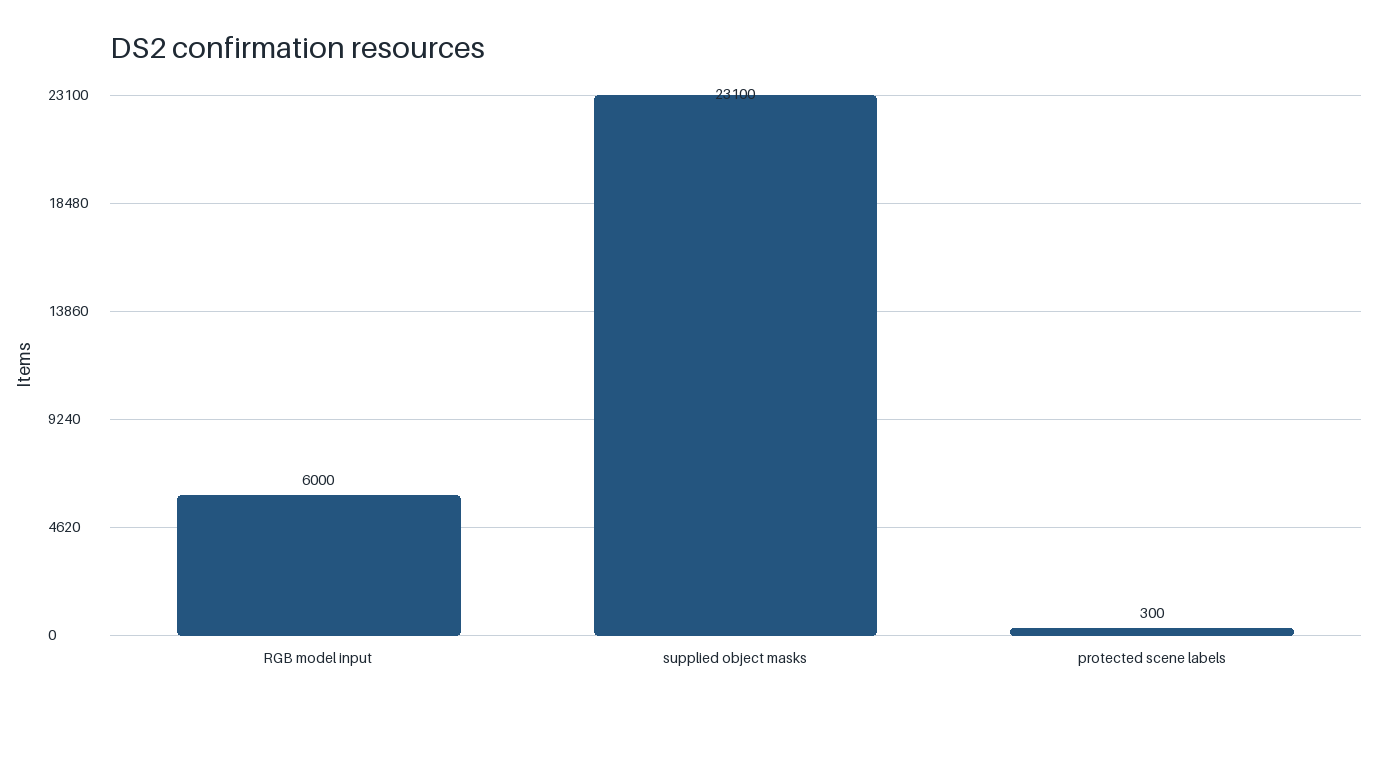

In [5]:
import pandas as pd

from visual_peer_inspector.evidence import save_bar_chart
from visual_peer_inspector.workflows.sam_confirmation_ds2 import _artifact_manifest

SAFE_ROOT = OUTPUT_ROOT / "safe"
SAFE_ROOT.mkdir(parents=True, exist_ok=True)
summary = pd.DataFrame([
    {"resource": "RGB model input", "items": release_record["rgb_package"]["image_count"], "model_facing": True},
    {"resource": "supplied object masks", "items": release_record["geometry_package"]["visible_object_view_count"], "model_facing": True},
    {"resource": "protected scene labels", "items": release_record["attributes_package"]["scene_count"], "model_facing": False},
])
summary.to_csv(SAFE_ROOT / "resource_summary.csv", index=False)
gates = pd.DataFrame([
    {"gate": "frozen membership", "passed": release_record["cohort"]["membership_sha256"] == DS2_CONFIRM_CONTRACT.membership_sha256},
    {"gate": "RGB coverage", "passed": release_record["rgb_package"]["image_count"] == DS2_CONFIRM_CONTRACT.image_count},
    {"gate": "RGB integrity", "passed": release_record["rgb_package"]["all_checks_passed"]},
    {"gate": "repeat build reused all RGB files", "passed": release_record["rgb_build"]["files_reused_this_run"] == DS2_CONFIRM_CONTRACT.image_count and release_record["rgb_build"]["files_written_this_run"] == 0},
    {"gate": "repeat build kept package identity", "passed": repeat_identity_matches},
    {"gate": "model input labels absent", "passed": not release_record["boundary"]["model_input_contains_labels"]},
    {"gate": "evaluator separated", "passed": not release_record["boundary"]["evaluator_attributes_model_facing"]},
])
gates.to_csv(SAFE_ROOT / "validation_gates.csv", index=False)
publication = pd.DataFrame([
    {
        "resource": "RGB model input",
        "expected_kaggle_dataset": "vpi-toysad-ds2-confirmation-rgb",
        "package_sha256": release_record["rgb_package"]["content_checksums_sha256"],
        "items": release_record["rgb_package"]["image_count"],
    },
    {
        "resource": "supplied geometry",
        "expected_kaggle_dataset": "vpi-toysad-ds2-confirmation-geometry",
        "package_sha256": release_record["geometry_package"]["content_checksums_sha256"],
        "items": release_record["geometry_package"]["visible_object_view_count"],
    },
    {
        "resource": "protected evaluator attributes",
        "expected_kaggle_dataset": "vpi-toysad-ds2-confirmation-evaluator",
        "package_sha256": release_record["attributes_package"]["content_checksums_sha256"],
        "items": release_record["attributes_package"]["scene_count"],
    },
])
publication.to_csv(SAFE_ROOT / "resource_publication.csv", index=False)
safe_record = {
    "schema_version": 1,
    "stage": "ds2_confirmation_input_release",
    "status": "completed",
    "cohort_id": DS2_CONFIRM_CONTRACT.cohort_id,
    "membership_sha256": DS2_CONFIRM_CONTRACT.membership_sha256,
    "scene_count": DS2_CONFIRM_CONTRACT.scene_count,
    "image_count": DS2_CONFIRM_CONTRACT.image_count,
    "asset_group_count": DS2_CONFIRM_CONTRACT.asset_group_count,
    "all_completion_gates_passed": bool(gates["passed"].all()),
}
(SAFE_ROOT / "run_record.json").write_text(json.dumps(safe_record, indent=2, sort_keys=True) + "\n", encoding="utf-8")
save_bar_chart(summary["resource"].tolist(), summary["items"].tolist(), SAFE_ROOT / "resource_counts.png", title="DS2 confirmation resources", y_label="Items", show_values=True)
_artifact_manifest(SAFE_ROOT)
display(gates)
display(summary)
display(publication)
display(NotebookImage(filename=str(SAFE_ROOT / "resource_counts.png")))
if not gates["passed"].all():
    raise RuntimeError("DS2 release acceptance failed")

## ClearML finalisation

Tracking starts only after the packages, tables, chart, run record, and checksums are complete. The isolated process receives only the safe aggregate folder. A tracking timeout cannot stop or invalidate the completed release.

In [6]:
if EXECUTION_ENVIRONMENT == "kaggle":
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(CODE_ROOT / "requirements/confirmation-tracking-lock.txt")], check=True, timeout=180)
    except Exception as error:
        print(f"ClearML dependency setup was unavailable: {type(error).__name__}")
tracking_receipt = run_clearml_finalizer(
    SAFE_ROOT,
    "ds2_confirmation_input_release",
    "ds2-confirmation-release",
    ["notebook-08a", "ds2", "confirmation", "kaggle"],
    OUTPUT_ROOT / "clearml_receipt.json",
)
display(tracking_receipt)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.2 MB/s eta 0:00:00


{'mode': 'disabled',
 'run_status': 'completed',
 'safe_manifest_sha256': '3ba92adc302c7d0609778697dc82a49607cab722b55b3489c08047659dfe69e2',
 'schema_version': 1,
 'stage': 'ds2_confirmation_input_release_clearml_finalisation',
 'status': 'disabled',
 'task_id': None,
 'tracking_attempt_count': 0,
 'tracking_retry_count': 0,
 'tracking_transient_failure_count': 0}

## Build compact verified downloads

The expanded RGB, geometry, and evaluator resources stay outside the notebook output. They are published as separate private Kaggle datasets. This notebook keeps aggregate release evidence, the sanitized ClearML receipt, and checksums in `/kaggle/working`.

In [7]:
BUNDLE_ROOT = (
    Path("/kaggle/working/notebook08a_bundles")
    if EXECUTION_ENVIRONMENT == "kaggle"
    else OUTPUT_ROOT.parent / "notebook08a_bundles"
)
verification_path = BUNDLE_ROOT / "ds2-confirmation-release-verification.json"
if not verification_path.is_file():
    subprocess.run(
        [
            sys.executable,
            str(CODE_ROOT / "scripts/package_kaggle_stage_output.py"),
            "--stage-root", str(OUTPUT_ROOT),
            "--output-root", str(BUNDLE_ROOT),
            "--stage-name", "ds2-confirmation-release",
            "--review-path", "clearml_receipt.json",
        ],
        check=True,
        env=code_environment(),
    )
bundle_record = json.loads(verification_path.read_text(encoding="utf-8"))
display(pd.DataFrame(bundle_record["archives"]))
print(f"Verified downloads: {BUNDLE_ROOT}")

{"archives": [{"path": "ds2-confirmation-release-repository-evidence.zip", "sha256": "27d1c8e43c22deb25207cc51b962c5886e060944d203eaca66548dea40b20ae5", "size_bytes": 18767, "source_file_count": 6}, {"path": "ds2-confirmation-release-review-evidence.zip", "sha256": "9d2d1c729dfbb1fdf51911b33888e1decc81a0b7e24b92f2509df224038d220b", "size_bytes": 386, "source_file_count": 1}], "downstream_file_count": 0, "review_file_count": 1, "safe_file_count": 6, "safe_manifest_sha256": "3ba92adc302c7d0609778697dc82a49607cab722b55b3489c08047659dfe69e2", "schema_version": 1, "stage": "ds2-confirmation-release", "status": "completed"}


,path,sha256,size_bytes,source_file_count
0,ds2-confirmation-release-repository-evidence.zip,27d1c8e43c22deb25207cc51b962c5886e060944d203ea...,18767,6
1,ds2-confirmation-release-review-evidence.zip,9d2d1c729dfbb1fdf51911b33888e1decc81a0b7e24b92...,386,1


Verified downloads: /kaggle/working/notebook08a_bundles


## Output boundary

Publish `model-input` and `oracle-geometry` as separate private Kaggle resources for Notebook 08B. Attach `evaluator-attributes` only to Notebook 08C. Do not attach the protected evaluator resource to a model job.